# GPU-Based K-Means Clustering, Live CUDA Lab
**PGD AI (IIT Jodhpur) Project · GPU Programming · Problem 5**

## 1 · Check the GPU

In [5]:
!nvidia-smi
!nvcc --version | tail -1

Sun Oct 25 17:59:36 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   38C    P8             11W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 2 · Write the project sources
The cells below write the exact files from the project repository (`src/`, `python/`).

In [6]:
%%writefile kmeans_cuda.cu
/*
 * kmeans_cuda.cu  --  GPU-Based K-Means Clustering (CUDA)
 * PGD AI (IIT Jodhpur) Project: "GPU-Based K-Means Clustering: Atomic vs. Reduction
 *                  Strategies for Parallel Centroid Update"
 *
 * Two centroid-update strategies are implemented and compared:
 *   MODE_ATOMIC    : every thread atomically adds its point into global
 *                    per-cluster sums (simple, contended, non-deterministic).
 *   MODE_REDUCTION : block-level privatisation in shared memory, then a
 *                    deterministic hierarchical reduction of per-block partials
 *                    (no global atomics on the hot path).
 */

#ifdef _MSC_VER
#define _CRT_SECURE_NO_WARNINGS
#endif
#include <cuda_runtime.h>
#include <cstdio>
#include <cstdlib>
#include <cstring>
#include <cmath>
#include <cfloat>
#include <vector>
#include <string>
#include <random>
#include <algorithm>

#define CUDA_CHECK(call)                                                        \
    do {                                                                        \
        cudaError_t err__ = (call);                                             \
        if (err__ != cudaSuccess) {                                             \
            fprintf(stderr, "CUDA error %s at %s:%d: %s\n", #call, __FILE__,    \
                    __LINE__, cudaGetErrorString(err__));                       \
            exit(EXIT_FAILURE);                                                 \
        }                                                                       \
    } while (0)

enum Mode { MODE_ATOMIC = 0, MODE_REDUCTION = 1 };

static const int BLOCK = 256;            // threads per block (assign/update)
static const int MAX_SHARED_FLOATS = 12000; // 48 KB / 4 bytes, keep margin

/* ------------------------------------------------------------------------ */
/* Kernel 1: assignment step. One thread per point; centroids in shared mem. */
/* ------------------------------------------------------------------------ */
__global__ void assign_kernel(const float* __restrict__ points,
                              const float* __restrict__ centroids,
                              int* __restrict__ assign,
                              int* __restrict__ changed_count,
                              int N, int D, int K, int use_shared)
{
    extern __shared__ float s_cent[];       // K*D floats when use_shared

    const float* cent = centroids;
    if (use_shared) {
        for (int idx = threadIdx.x; idx < K * D; idx += blockDim.x)
            s_cent[idx] = centroids[idx];
        cent = s_cent;
    }
    __syncthreads();

    int i = blockIdx.x * blockDim.x + threadIdx.x;
    int local_changed = 0;
    if (i < N) {
        const float* p = points + (size_t)i * D;
        float best = FLT_MAX;
        int best_k = 0;
        for (int k = 0; k < K; ++k) {
            const float* c = cent + k * D;
            float dist = 0.f;
            for (int j = 0; j < D; ++j) {
                float diff = p[j] - c[j];
                dist = fmaf(diff, diff, dist);
            }
            if (dist < best) { best = dist; best_k = k; }
        }
        if (assign[i] != best_k) { assign[i] = best_k; local_changed = 1; }
    }

    /* block-level count of changed assignments, then ONE global atomic */
    local_changed = __syncthreads_count(local_changed);
    if (threadIdx.x == 0 && local_changed > 0) atomicAdd(changed_count, local_changed);
}

/* ------------------------------------------------------------------------ */
/* Kernel 2a: ATOMIC update. Each thread atomically adds its coordinates.   */
/* ------------------------------------------------------------------------ */
__global__ void update_atomic_kernel(const float* __restrict__ points,
                                     const int* __restrict__ assign,
                                     float* __restrict__ sums,
                                     int* __restrict__ counts,
                                     int N, int D)
{
    int i = blockIdx.x * blockDim.x + threadIdx.x;
    if (i >= N) return;
    int k = assign[i];
    const float* p = points + (size_t)i * D;
    for (int j = 0; j < D; ++j) atomicAdd(&sums[k * D + j], p[j]);
    atomicAdd(&counts[k], 1);
}

/* ------------------------------------------------------------------------ */
/* Kernel 2b: REDUCTION update, stage 1. Block-private accumulation in      */
/* shared memory (shared-memory atomics are on-chip and cheap), partial      */
/* sums written to a per-block slot -> no global atomics at all.             */
/* ------------------------------------------------------------------------ */
__global__ void update_partial_kernel(const float* __restrict__ points,
                                      const int* __restrict__ assign,
                                      float* __restrict__ partial_sums,   // [gridDim.x][K*D]
                                      int* __restrict__ partial_counts,   // [gridDim.x][K]
                                      int N, int D, int K)
{
    extern __shared__ float s_sums[];             // K*D floats
    int* s_counts = (int*)(s_sums + K * D);       // K ints after the floats

    for (int idx = threadIdx.x; idx < K * D; idx += blockDim.x) s_sums[idx] = 0.f;
    for (int idx = threadIdx.x; idx < K; idx += blockDim.x) s_counts[idx] = 0;
    __syncthreads();

    /* grid-stride loop: each block owns a contiguous stripe of points */
    for (int i = blockIdx.x * blockDim.x + threadIdx.x; i < N; i += gridDim.x * blockDim.x) {
        int k = assign[i];
        const float* p = points + (size_t)i * D;
        for (int j = 0; j < D; ++j) atomicAdd(&s_sums[k * D + j], p[j]);
        atomicAdd(&s_counts[k], 1);
    }
    __syncthreads();

    float* out_s = partial_sums + (size_t)blockIdx.x * K * D;
    int*   out_c = partial_counts + (size_t)blockIdx.x * K;
    for (int idx = threadIdx.x; idx < K * D; idx += blockDim.x) out_s[idx] = s_sums[idx];
    for (int idx = threadIdx.x; idx < K; idx += blockDim.x) out_c[idx] = s_counts[idx];
}

/* Stage 2: deterministic reduction over blocks. One thread per (k,j) cell. */
__global__ void reduce_partials_kernel(const float* __restrict__ partial_sums,
                                       const int* __restrict__ partial_counts,
                                       float* __restrict__ sums,
                                       int* __restrict__ counts,
                                       int num_blocks, int D, int K)
{
    int cell = blockIdx.x * blockDim.x + threadIdx.x;     // 0 .. K*D-1
    if (cell < K * D) {
        float acc = 0.f;
        for (int b = 0; b < num_blocks; ++b) acc += partial_sums[(size_t)b * K * D + cell];
        sums[cell] = acc;
    }
    if (cell < K) {
        int acc = 0;
        for (int b = 0; b < num_blocks; ++b) acc += partial_counts[(size_t)b * K + cell];
        counts[cell] = acc;
    }
}

/* ------------------------------------------------------------------------ */
/* Kernel 3: finalise centroids = sums / counts and reduce max shift^2.      */
/* atomicMax on float bits is valid because shifts are non-negative.         */
/* ------------------------------------------------------------------------ */
__global__ void finalize_kernel(float* __restrict__ centroids,
                                const float* __restrict__ sums,
                                const int* __restrict__ counts,
                                float* __restrict__ max_shift_sq,
                                int D, int K)
{
    __shared__ float s_max[BLOCK];
    int k = blockIdx.x * blockDim.x + threadIdx.x;
    float shift = 0.f;
    if (k < K) {
        int c = counts[k];
        if (c > 0) {
            float inv = 1.f / (float)c;
            for (int j = 0; j < D; ++j) {
                float newv = sums[k * D + j] * inv;
                float diff = newv - centroids[k * D + j];
                shift = fmaf(diff, diff, shift);
                centroids[k * D + j] = newv;
            }
        } /* empty cluster: keep previous centroid */
    }
    s_max[threadIdx.x] = shift;
    __syncthreads();
    for (int s = blockDim.x / 2; s > 0; s >>= 1) {
        if (threadIdx.x < s) s_max[threadIdx.x] = fmaxf(s_max[threadIdx.x], s_max[threadIdx.x + s]);
        __syncthreads();
    }
    if (threadIdx.x == 0) atomicMax((int*)max_shift_sq, __float_as_int(s_max[0]));
}

/* ------------------------------------------------------------------------ */
/* Host helpers                                                              */
/* ------------------------------------------------------------------------ */
static bool read_bin(const std::string& path, std::vector<float>& data, int& N, int& D)
{
    FILE* f = fopen(path.c_str(), "rb");
    if (!f) { fprintf(stderr, "cannot open %s\n", path.c_str()); return false; }
    if (fread(&N, 4, 1, f) != 1 || fread(&D, 4, 1, f) != 1) { fclose(f); return false; }
    data.resize((size_t)N * D);
    size_t got = fread(data.data(), 4, data.size(), f);
    fclose(f);
    return got == data.size();
}

static void write_bin_f(const std::string& path, const std::vector<float>& data, int N, int D)
{
    FILE* f = fopen(path.c_str(), "wb");
    if (!f) return;
    fwrite(&N, 4, 1, f); fwrite(&D, 4, 1, f);
    fwrite(data.data(), 4, data.size(), f);
    fclose(f);
}

static void write_bin_i(const std::string& path, const std::vector<int>& data, int N)
{
    FILE* f = fopen(path.c_str(), "wb");
    if (!f) return;
    fwrite(&N, 4, 1, f);
    fwrite(data.data(), 4, data.size(), f);
    fclose(f);
}

static void gen_blobs(int N, int D, int K, unsigned seed, std::vector<float>& pts)
{
    std::mt19937 rng(seed);
    std::uniform_real_distribution<float> uc(-10.f, 10.f);
    std::normal_distribution<float> noise(0.f, 1.0f);
    std::vector<float> centers((size_t)K * D);
    for (auto& v : centers) v = uc(rng);
    pts.resize((size_t)N * D);
    for (int i = 0; i < N; ++i) {
        int k = i % K;
        for (int j = 0; j < D; ++j) pts[(size_t)i * D + j] = centers[k * D + j] + noise(rng);
    }
    /* shuffle rows so clusters are interleaved */
    std::vector<int> perm(N);
    for (int i = 0; i < N; ++i) perm[i] = i;
    std::shuffle(perm.begin(), perm.end(), rng);
    std::vector<float> out((size_t)N * D);
    for (int i = 0; i < N; ++i)
        memcpy(&out[(size_t)i * D], &pts[(size_t)perm[i] * D], D * sizeof(float));
    pts.swap(out);
}

int main(int argc, char** argv)
{
    std::string data_path, init_path, out_assign = "assign.bin", out_cent = "centroids.bin";
    std::string dump_path;
    int K = 0, max_iters = 100, N = 0, D = 0;
    float tol = 1e-4f;
    Mode mode = MODE_REDUCTION;
    unsigned seed = 42;
    bool gen = false, verbose = false;
    int genN = 0, genD = 0;

    for (int a = 1; a < argc; ++a) {
        std::string s = argv[a];
        auto next = [&](const char* what) -> const char* {
            if (a + 1 >= argc) { fprintf(stderr, "missing value for %s\n", what); exit(1); }
            return argv[++a];
        };
        if      (s == "--data")       data_path  = next("--data");
        else if (s == "--init")       init_path  = next("--init");
        else if (s == "--k")          K          = atoi(next("--k"));
        else if (s == "--iters")      max_iters  = atoi(next("--iters"));
        else if (s == "--tol")        tol        = (float)atof(next("--tol"));
        else if (s == "--seed")       seed       = (unsigned)atoi(next("--seed"));
        else if (s == "--out-assign") out_assign = next("--out-assign");
        else if (s == "--out-cent")   out_cent   = next("--out-cent");
        else if (s == "--dump")       dump_path  = next("--dump");
        else if (s == "--verbose")    verbose    = true;
        else if (s == "--mode") {
            std::string m = next("--mode");
            mode = (m == "atomic") ? MODE_ATOMIC : MODE_REDUCTION;
        }
        else if (s == "--gen") {
            gen = true;
            genN = atoi(next("--gen N")); genD = atoi(next("D")); K = atoi(next("K"));
        }
        else { fprintf(stderr, "unknown arg %s\n", s.c_str()); return 1; }
    }
    if (K <= 0) { fprintf(stderr, "--k required\n"); return 1; }

    std::vector<float> h_points, h_cent;
    if (gen) {
        N = genN; D = genD;
        gen_blobs(N, D, K, seed, h_points);
        if (!dump_path.empty()) write_bin_f(dump_path, h_points, N, D);
    } else {
        if (!read_bin(data_path, h_points, N, D)) return 1;
    }
    if (!init_path.empty()) {
        int kk, dd;
        if (!read_bin(init_path, h_cent, kk, dd) || kk != K || dd != D) {
            fprintf(stderr, "bad init file\n"); return 1;
        }
    } else {
        /* deterministic init: first K points (same rule as the CPU reference) */
        h_cent.assign(h_points.begin(), h_points.begin() + (size_t)K * D);
    }

    const int use_shared = (K * D <= MAX_SHARED_FLOATS) ? 1 : 0;
    const int grid_assign = (N + BLOCK - 1) / BLOCK;
    int dev = 0; cudaDeviceProp prop; CUDA_CHECK(cudaGetDeviceProperties(&prop, dev));
    /* for the reduction path use ~8 blocks per SM so partials stay small */
    int grid_partial = prop.multiProcessorCount * 8;
    if (grid_partial > grid_assign) grid_partial = grid_assign;
    const size_t shm_cent  = use_shared ? (size_t)K * D * sizeof(float) : 0;
    const size_t shm_part  = (size_t)K * D * sizeof(float) + (size_t)K * sizeof(int);
    if (mode == MODE_REDUCTION && shm_part > 48 * 1024) {
        fprintf(stderr, "K*D too large for shared-memory privatisation; use --mode atomic\n");
        return 1;
    }

    float *d_points, *d_cent, *d_sums, *d_partial_sums, *d_max_shift;
    int   *d_assign, *d_counts, *d_partial_counts, *d_changed;
    CUDA_CHECK(cudaMalloc(&d_points, (size_t)N * D * sizeof(float)));
    CUDA_CHECK(cudaMalloc(&d_cent,   (size_t)K * D * sizeof(float)));
    CUDA_CHECK(cudaMalloc(&d_sums,   (size_t)K * D * sizeof(float)));
    CUDA_CHECK(cudaMalloc(&d_assign, (size_t)N * sizeof(int)));
    CUDA_CHECK(cudaMalloc(&d_counts, (size_t)K * sizeof(int)));
    CUDA_CHECK(cudaMalloc(&d_changed, sizeof(int)));
    CUDA_CHECK(cudaMalloc(&d_max_shift, sizeof(float)));
    CUDA_CHECK(cudaMalloc(&d_partial_sums,   (size_t)grid_partial * K * D * sizeof(float)));
    CUDA_CHECK(cudaMalloc(&d_partial_counts, (size_t)grid_partial * K * sizeof(int)));

    CUDA_CHECK(cudaMemcpy(d_points, h_points.data(), (size_t)N * D * sizeof(float), cudaMemcpyHostToDevice));
    CUDA_CHECK(cudaMemcpy(d_cent,   h_cent.data(),   (size_t)K * D * sizeof(float), cudaMemcpyHostToDevice));
    CUDA_CHECK(cudaMemset(d_assign, 0xFF, (size_t)N * sizeof(int)));   // -1 = unassigned

    cudaEvent_t ev0, ev1, evA, evB;
    CUDA_CHECK(cudaEventCreate(&ev0)); CUDA_CHECK(cudaEventCreate(&ev1));
    CUDA_CHECK(cudaEventCreate(&evA)); CUDA_CHECK(cudaEventCreate(&evB));
    float assign_ms = 0.f, update_ms = 0.f, t;
    const float tol_sq = tol * tol;
    int iters = 0, changed = 0; float max_shift_sq = 0.f;

    if (verbose)
        fprintf(stderr, "[host] gpu=%s SMs=%d | N=%d D=%d K=%d | mode=%s | grid_assign=%d grid_partial=%d BLOCK=%d | shared centroids=%s (%zu B) | tol=%.1e\n",
                prop.name, prop.multiProcessorCount, N, D, K, mode == MODE_ATOMIC ? "atomic" : "reduction",
                grid_assign, grid_partial, BLOCK, use_shared ? "yes" : "no", shm_cent, tol);
    CUDA_CHECK(cudaEventRecord(ev0));
    for (iters = 1; iters <= max_iters; ++iters) {
        CUDA_CHECK(cudaMemsetAsync(d_changed, 0, sizeof(int)));
        CUDA_CHECK(cudaMemsetAsync(d_max_shift, 0, sizeof(float)));
        CUDA_CHECK(cudaMemsetAsync(d_sums, 0, (size_t)K * D * sizeof(float)));
        CUDA_CHECK(cudaMemsetAsync(d_counts, 0, (size_t)K * sizeof(int)));

        CUDA_CHECK(cudaEventRecord(evA));
        assign_kernel<<<grid_assign, BLOCK, shm_cent>>>(d_points, d_cent, d_assign, d_changed, N, D, K, use_shared);
        CUDA_CHECK(cudaEventRecord(evB));
        CUDA_CHECK(cudaEventSynchronize(evB));
        CUDA_CHECK(cudaEventElapsedTime(&t, evA, evB)); assign_ms += t; float t_assign_iter = t;

        CUDA_CHECK(cudaEventRecord(evA));
        if (mode == MODE_ATOMIC) {
            update_atomic_kernel<<<grid_assign, BLOCK>>>(d_points, d_assign, d_sums, d_counts, N, D);
        } else {
            update_partial_kernel<<<grid_partial, BLOCK, shm_part>>>(d_points, d_assign, d_partial_sums, d_partial_counts, N, D, K);
            int cells = K * D, gr = (cells + BLOCK - 1) / BLOCK;
            reduce_partials_kernel<<<gr, BLOCK>>>(d_partial_sums, d_partial_counts, d_sums, d_counts, grid_partial, D, K);
        }
        finalize_kernel<<<(K + BLOCK - 1) / BLOCK, BLOCK>>>(d_cent, d_sums, d_counts, d_max_shift, D, K);
        CUDA_CHECK(cudaEventRecord(evB));
        CUDA_CHECK(cudaEventSynchronize(evB));
        CUDA_CHECK(cudaEventElapsedTime(&t, evA, evB)); update_ms += t;
        CUDA_CHECK(cudaGetLastError());

        /* ONLY two scalars cross the PCIe bus per iteration */
        CUDA_CHECK(cudaMemcpy(&changed, d_changed, sizeof(int), cudaMemcpyDeviceToHost));
        CUDA_CHECK(cudaMemcpy(&max_shift_sq, d_max_shift, sizeof(float), cudaMemcpyDeviceToHost));
        if (verbose)
            fprintf(stderr, "[iter %3d] assign=%.3fms update=%.3fms changed=%d max_shift=%.3e%s\n",
                    iters, t_assign_iter, t, changed, sqrtf(max_shift_sq),
                    (changed == 0) ? "  => CONVERGED (no change)" : (max_shift_sq < tol_sq) ? "  => CONVERGED (shift < tol)" : "");
        if (changed == 0 || max_shift_sq < tol_sq) break;
    }
    if (iters > max_iters) iters = max_iters;
    CUDA_CHECK(cudaEventRecord(ev1));
    CUDA_CHECK(cudaEventSynchronize(ev1));
    float total_ms; CUDA_CHECK(cudaEventElapsedTime(&total_ms, ev0, ev1));

    std::vector<int> h_assign(N);
    CUDA_CHECK(cudaMemcpy(h_assign.data(), d_assign, (size_t)N * sizeof(int), cudaMemcpyDeviceToHost));
    CUDA_CHECK(cudaMemcpy(h_cent.data(), d_cent, (size_t)K * D * sizeof(float), cudaMemcpyDeviceToHost));

    /* inertia (sum of squared distances) on host for reporting */
    double inertia = 0.0;
    for (int i = 0; i < N; ++i) {
        int k = h_assign[i];
        for (int j = 0; j < D; ++j) {
            double diff = (double)h_points[(size_t)i * D + j] - h_cent[k * D + j];
            inertia += diff * diff;
        }
    }
    write_bin_i(out_assign, h_assign, N);
    write_bin_f(out_cent, h_cent, K, D);

    printf("RESULT mode=%s N=%d D=%d K=%d iters=%d changed_last=%d max_shift=%.3e "
           "time_ms=%.3f assign_ms=%.3f update_ms=%.3f inertia=%.6e shared_centroids=%d gpu=\"%s\"\n",
           mode == MODE_ATOMIC ? "atomic" : "reduction", N, D, K, iters, changed, sqrtf(max_shift_sq),
           total_ms, assign_ms, update_ms, inertia, use_shared, prop.name);

    cudaFree(d_points); cudaFree(d_cent); cudaFree(d_sums); cudaFree(d_assign); cudaFree(d_counts);
    cudaFree(d_changed); cudaFree(d_max_shift); cudaFree(d_partial_sums); cudaFree(d_partial_counts);
    return 0;
}


Overwriting kmeans_cuda.cu


In [7]:
%%writefile kmeans_cpu.c
/* kmeans_cpu.c  (portable: gcc/clang on Linux/macOS, MSVC cl.exe on Windows) -- sequential reference implementation (same init rule:
 * first K points; same convergence rule) used to validate the GPU output
 * and to measure CPU baseline time.  Build: gcc -O3 -o kmeans_cpu kmeans_cpu.c -lm
 * Usage: ./kmeans_cpu --data points.bin --k 8 [--iters 100] [--tol 1e-4]
 *                     [--out-assign a.bin] [--out-cent c.bin]            */
#include <stdio.h>
#include <stdlib.h>
#include <string.h>
#include <math.h>
#include <float.h>
#include <time.h>
#ifdef _WIN32
  #define WIN32_LEAN_AND_MEAN
  #include <windows.h>
  static double now_ms(void){ LARGE_INTEGER f,c; QueryPerformanceFrequency(&f); QueryPerformanceCounter(&c); return 1e3*(double)c.QuadPart/(double)f.QuadPart; }
  #define _CRT_SECURE_NO_WARNINGS
#else
  static double now_ms(void){ struct timespec t; clock_gettime(CLOCK_MONOTONIC,&t); return t.tv_sec*1e3+t.tv_nsec/1e6; }
#endif

int main(int argc, char** argv){
    const char *data=NULL,*oa="assign_cpu.bin",*oc="centroids_cpu.bin"; int K=0,max_iters=100; float tol=1e-4f;
    for(int a=1;a<argc;a++){
        if(!strcmp(argv[a],"--data")) data=argv[++a];
        else if(!strcmp(argv[a],"--k")) K=atoi(argv[++a]);
        else if(!strcmp(argv[a],"--iters")) max_iters=atoi(argv[++a]);
        else if(!strcmp(argv[a],"--tol")) tol=(float)atof(argv[++a]);
        else if(!strcmp(argv[a],"--out-assign")) oa=argv[++a];
        else if(!strcmp(argv[a],"--out-cent")) oc=argv[++a];
    }
    if(!data||K<=0){fprintf(stderr,"usage: --data f.bin --k K\n");return 1;}
    FILE* f=fopen(data,"rb"); if(!f){perror("data");return 1;}
    int N,D; if(fread(&N,4,1,f)!=1||fread(&D,4,1,f)!=1) return 1;
    float* P=malloc((size_t)N*D*4); if(fread(P,4,(size_t)N*D,f)!=(size_t)N*D) return 1; fclose(f);
    float* C=malloc((size_t)K*D*4); memcpy(C,P,(size_t)K*D*4);
    float* S=malloc((size_t)K*D*4); int* cnt=malloc(K*4); int* A=malloc((size_t)N*4);
    for(int i=0;i<N;i++) A[i]=-1;
    double t0=now_ms(); int it, changed=0; float maxshift=0;
    for(it=1;it<=max_iters;it++){
        changed=0; memset(S,0,(size_t)K*D*4); memset(cnt,0,K*4);
        for(int i=0;i<N;i++){
            const float* p=P+(size_t)i*D; float best=FLT_MAX; int bk=0;
            for(int k=0;k<K;k++){ float d=0; for(int j=0;j<D;j++){float df=p[j]-C[k*D+j]; d=fmaf(df,df,d);} if(d<best){best=d;bk=k;} }
            if(A[i]!=bk){A[i]=bk;changed++;}
            for(int j=0;j<D;j++) S[bk*D+j]+=p[j]; cnt[bk]++;
        }
        maxshift=0;
        for(int k=0;k<K;k++) if(cnt[k]>0){ float sh=0; for(int j=0;j<D;j++){ float nv=S[k*D+j]/cnt[k]; float df=nv-C[k*D+j]; sh+=df*df; C[k*D+j]=nv;} if(sh>maxshift)maxshift=sh; }
        if(changed==0||maxshift<tol*tol) break;
    }
    if(it>max_iters) it=max_iters;
    double ms=now_ms()-t0; double inertia=0;
    for(int i=0;i<N;i++) for(int j=0;j<D;j++){double df=P[(size_t)i*D+j]-C[A[i]*D+j]; inertia+=df*df;}
    f=fopen(oa,"wb"); fwrite(&N,4,1,f); fwrite(A,4,N,f); fclose(f);
    f=fopen(oc,"wb"); fwrite(&K,4,1,f); fwrite(&D,4,1,f); fwrite(C,4,(size_t)K*D,f); fclose(f);
    printf("RESULT mode=cpu N=%d D=%d K=%d iters=%d changed_last=%d max_shift=%.3e time_ms=%.3f inertia=%.6e\n",N,D,K,it,changed,sqrtf(maxshift),ms,inertia);
    return 0;
}


Writing kmeans_cpu.c


In [8]:
%%writefile kmeans_io.py
"""Binary I/O shared by all Python tools."""
import numpy as np

def write_points(path, X):
    X = np.ascontiguousarray(X, dtype=np.float32)
    with open(path, "wb") as f:
        np.array(X.shape, dtype=np.int32).tofile(f)
        X.tofile(f)

def read_points(path):
    with open(path, "rb") as f:
        n, d = np.fromfile(f, dtype=np.int32, count=2)
        return np.fromfile(f, dtype=np.float32, count=n * d).reshape(n, d)

def read_assign(path):
    with open(path, "rb") as f:
        n = int(np.fromfile(f, dtype=np.int32, count=1)[0])
        return np.fromfile(f, dtype=np.int32, count=n)


Overwriting kmeans_io.py


In [9]:
%%writefile kmeans_numpy.py
"""Vectorised NumPy K-Means reference (identical init + stopping rule to the CUDA code).
Returns assignments, centroids, iterations, per-iteration history."""
import numpy as np

def kmeans_numpy(X, K, max_iters=100, tol=1e-4, init=None, history=False):
    X = X.astype(np.float32)
    C = (X[:K] if init is None else init).astype(np.float32).copy()
    A = np.full(len(X), -1, dtype=np.int32)
    hist = []
    for it in range(1, max_iters + 1):
        # squared distances via ||x||^2 - 2 x.c + ||c||^2  (N x K), argmin over K
        d2 = (X * X).sum(1)[:, None] - 2 * X @ C.T + (C * C).sum(1)[None, :]
        newA = d2.argmin(1).astype(np.int32)
        changed = int((newA != A).sum()); A = newA
        newC = C.copy(); max_shift2 = 0.0
        for k in range(K):
            m = A == k
            if m.any():
                newC[k] = X[m].mean(0)
                max_shift2 = max(max_shift2, float(((newC[k] - C[k]) ** 2).sum()))
        C = newC
        if history:
            inertia = float(((X - C[A]) ** 2).sum()); hist.append((it, changed, np.sqrt(max_shift2), inertia))
        if changed == 0 or max_shift2 < tol * tol:
            break
    return A, C, it, hist


Overwriting kmeans_numpy.py


In [10]:
%%writefile verify.py
"""Verify GPU outputs against the CPU/NumPy reference."""
import sys, numpy as np
from kmeans_io import read_points, read_assign

def inertia(X, C, A): return float(((X - C[A]) ** 2).sum())

X = read_points(sys.argv[1]); Cr = read_points(sys.argv[2]); Ar = read_assign(sys.argv[3])
print(f"reference: inertia={inertia(X, Cr, Ar):.6e}")
ok = True
for i in range(4, len(sys.argv), 2):
    C = read_points(sys.argv[i]); A = read_assign(sys.argv[i + 1])
    agree = 100.0 * (A == Ar).mean(); err = float(np.abs(C - Cr).max())
    inr = inertia(X, C, A); rel = abs(inr - inertia(X, Cr, Ar)) / inertia(X, Cr, Ar)
    status = "PASS" if (agree > 99.9 and err < 1e-3) else "CHECK"
    if status != "PASS": ok = False
    print(f"{sys.argv[i]:>28s}: agreement={agree:7.3f}%  centroid_max_abs_err={err:.2e}  inertia={inr:.6e} (rel diff {rel:.1e})  {status}")
sys.exit(0 if ok else 1)


Overwriting verify.py


In [11]:
%%writefile benchmark.py
"""Benchmark sweep over N, D, K for atomic vs reduction (and CPU baseline)."""
import argparse, subprocess, re, csv, os, tempfile, numpy as np
from kmeans_io import write_points

ap = argparse.ArgumentParser()
ap.add_argument("--exe", required=True); ap.add_argument("--cpu", default=None)
ap.add_argument("--out", required=True)
ap.add_argument("--sizes", default="100000,1000000,4000000")
ap.add_argument("--dims", default="2,8,32"); ap.add_argument("--ks", default="4,16,64")
ap.add_argument("--repeat", type=int, default=3); ap.add_argument("--cpu-max-n", type=int, default=1000000)
a = ap.parse_args()
os.makedirs(os.path.dirname(a.out) or ".", exist_ok=True)
rows = []
def run(cmd):
    out = subprocess.run(cmd, capture_output=True, text=True, check=True).stdout
    m = re.search(r"RESULT (.*)", out); kv = dict(p.split("=", 1) for p in re.findall(r'(\w+=(?:"[^"]*"|\S+))', m.group(1)))
    return {k: v.strip('"') for k, v in kv.items()}
rng = np.random.default_rng(0)
for N in map(int, a.sizes.split(",")):
    for D in map(int, a.dims.split(",")):
        for K in map(int, a.ks.split(",")):
            tmp = tempfile.gettempdir(); path = os.path.join(tmp, f"bench_{N}_{D}_{K}.bin")
            ta, tc = os.path.join(tmp, "a.bin"), os.path.join(tmp, "c.bin")
            centers = rng.uniform(-10, 10, (K, D)).astype(np.float32)
            X = centers[rng.integers(0, K, N)] + rng.normal(0, 1, (N, D)).astype(np.float32)
            write_points(path, X)
            for mode in ("atomic", "reduction"):
                for r in range(a.repeat):
                    res = run([a.exe, "--data", path, "--k", str(K), "--mode", mode, "--iters", "50",
                               "--out-assign", ta, "--out-cent", tc])
                    res["rep"] = r; rows.append(res); print(res)
            if a.cpu and N <= a.cpu_max_n:
                res = run([a.cpu, "--data", path, "--k", str(K), "--iters", "50",
                           "--out-assign", ta, "--out-cent", tc])
                res["rep"] = 0; rows.append(res); print(res)
            os.remove(path)
keys = sorted({k for r in rows for k in r})
with open(a.out, "w", newline="") as f:
    w = csv.DictWriter(f, fieldnames=keys); w.writeheader(); w.writerows(rows)
print("wrote", a.out)


Writing benchmark.py


In [12]:
%%writefile plot_results.py
"""Plot measured GPU benchmark results (benchmark.py CSV) -> 3-panel figure.
Usage: python plot_results.py results/benchmark_T4_colab.csv figures/fig5_gpu_benchmark.png"""
import sys, csv, collections, matplotlib; matplotlib.use("Agg"); import matplotlib.pyplot as plt
rows = list(csv.DictReader(open(sys.argv[1])))
tot, upd = collections.defaultdict(list), collections.defaultdict(list)
for r in rows:
    k = (r["mode"], int(r["N"]), int(r["D"]), int(r["K"])); it = int(r["iters"])
    tot[k].append(float(r["time_ms"]) / it)
    if r["mode"] != "cpu": upd[k].append(float(r["update_ms"]) / it)
mean = lambda d, k: sum(d[k]) / len(d[k])
gpu = next((r["gpu"] for r in rows if r.get("gpu")), "GPU")
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
D, K = 8, 16
for mode, m in (("atomic", "o"), ("reduction", "s"), ("cpu", "^")):
    pts = sorted((n, mean(tot, k)) for k in tot if k[0] == mode and k[2] == D and k[3] == K for n in [k[1]])
    if pts: ax[0].loglog(*zip(*pts), m + "-", label=mode if mode != "cpu" else "CPU (1 core)")
ax[0].set_xlabel("N"); ax[0].set_ylabel("ms / iteration (total)"); ax[0].set_title(f"Total time vs N  (D={D}, K={K})"); ax[0].legend(); ax[0].grid(alpha=.3, which="both")
N = max(k[1] for k in tot)
for d, c in ((2, "C0"), (8, "C1"), (32, "C2")):
    for mode, ls, m in (("atomic", "--", "o"), ("reduction", "-", "s")):
        pts = sorted((k[3], mean(upd, k)) for k in upd if k[0] == mode and k[1] == N and k[2] == d)
        if pts: ax[1].loglog(*zip(*pts), ls, marker=m, color=c, label=f"{mode}, D={d}")
ax[1].set_xlabel("K"); ax[1].set_ylabel("update step ms / iteration"); ax[1].set_title(f"Centroid-update cost vs K  (N={N:,})"); ax[1].legend(fontsize=8, ncol=2); ax[1].grid(alpha=.3, which="both")
from matplotlib.ticker import NullFormatter, FixedLocator
ax[1].xaxis.set_major_locator(FixedLocator([4, 16, 64])); ax[1].set_xticklabels(["4", "16", "64"]); ax[1].xaxis.set_minor_formatter(NullFormatter())
N1 = 1_000_000; labels, sp_a, sp_r = [], [], []
for k in sorted({(k[2], k[3]) for k in tot if k[1] == N1}):
    c = mean(tot, ("cpu", N1, *k)); labels.append(f"D={k[0]}\nK={k[1]}")
    sp_a.append(c / mean(tot, ("atomic", N1, *k))); sp_r.append(c / mean(tot, ("reduction", N1, *k)))
x = range(len(labels)); ax[2].bar([i - 0.2 for i in x], sp_a, 0.4, label="atomic"); ax[2].bar([i + 0.2 for i in x], sp_r, 0.4, label="reduction")
ax[2].set_xticks(list(x)); ax[2].set_xticklabels(labels, fontsize=8); ax[2].set_ylabel("speed-up vs 1-core CPU (×)"); ax[2].set_title(f"Speed-up at N = {N1:,}"); ax[2].legend(); ax[2].grid(alpha=.3, axis="y")
fig.suptitle(f"Measured on {gpu} (Google Colab), 50 iterations, mean of 2 runs", fontsize=10)
plt.tight_layout(); plt.savefig(sys.argv[2], dpi=160); print("wrote", sys.argv[2])


Writing plot_results.py


## 3 · Compile

In [13]:
import subprocess, re
cc = subprocess.run(['nvidia-smi','--query-gpu=compute_cap','--format=csv,noheader'],capture_output=True,text=True).stdout.strip().replace('.','')
arch = f'sm_{cc}' if cc else 'sm_75'
print('compiling for', arch)
!nvcc -O3 -arch={arch} -lineinfo -o kmeans_cuda kmeans_cuda.cu && echo CUDA_BUILD_OK
!gcc -O3 -o kmeans_cpu kmeans_cpu.c -lm && echo CPU_BUILD_OK

compiling for sm_75
CUDA_BUILD_OK
CPU_BUILD_OK


## 4 · Generate data (200 000 points, D = 2, K = 8)
Gaussian blobs; the first K points are used as initial centroids by *every* implementation so results are directly comparable.

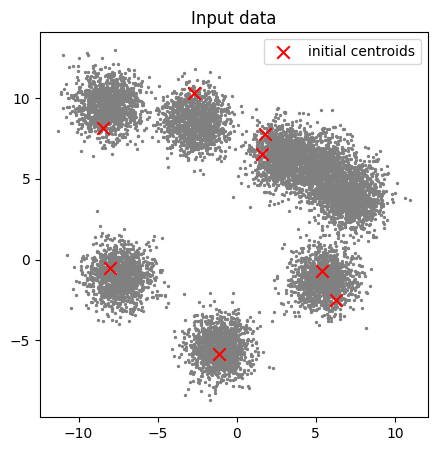

In [14]:
import numpy as np, matplotlib.pyplot as plt
from kmeans_io import *
rng = np.random.default_rng(42)
N, D, K = 200_000, 2, 8
centers = rng.uniform(-10, 10, (K, D)).astype(np.float32)
X = centers[rng.integers(0, K, N)] + rng.normal(0, 1.0, (N, D)).astype(np.float32)
write_points('blobs.bin', X)
plt.figure(figsize=(5,5)); plt.scatter(X[::20,0], X[::20,1], s=2, c='0.5'); plt.scatter(X[:K,0], X[:K,1], marker='x', c='red', s=80, label='initial centroids'); plt.legend(); plt.title('Input data'); plt.show()

## 5 · Run the GPU K-Means — both strategies — and the CPU reference

In [15]:
!./kmeans_cuda --data blobs.bin --k 8 --mode atomic    --out-assign a_atomic.bin --out-cent c_atomic.bin
!./kmeans_cuda --data blobs.bin --k 8 --mode reduction --verbose --out-assign a_red.bin --out-cent c_red.bin
!./kmeans_cpu  --data blobs.bin --k 8 --out-assign a_cpu.bin --out-cent c_cpu.bin

RESULT mode=atomic N=200000 D=2 K=8 iters=16 changed_last=0 max_shift=1.288e-05 time_ms=8.619 assign_ms=0.695 update_ms=7.241 inertia=3.736720e+05 shared_centroids=1 gpu="Tesla T4"
[host] gpu=Tesla T4 SMs=40 | N=200000 D=2 K=8 | mode=reduction | grid_assign=782 grid_partial=320 BLOCK=256 | shared centroids=yes (64 B) | tol=1.0e-04
[iter   1] assign=0.206ms update=0.096ms changed=200000 max_shift=2.757e+00
[iter   2] assign=0.037ms update=0.067ms changed=26369 max_shift=1.500e+00
[iter   3] assign=0.044ms update=0.064ms changed=15207 max_shift=7.729e-01
[iter   4] assign=0.031ms update=0.063ms changed=4530 max_shift=1.420e-01
[iter   5] assign=0.031ms update=0.063ms changed=1240 max_shift=4.080e-02
[iter   6] assign=0.031ms update=0.061ms changed=421 max_shift=1.801e-02
[iter   7] assign=0.031ms update=0.062ms changed=176 max_shift=9.000e-03
[iter   8] assign=0.031ms update=0.063ms changed=105 max_shift=5.160e-03
[iter   9] assign=0.031ms update=0.064ms changed=68 max_shift=3.735e-03
[i

## 6 · Validate GPU results against the CPU reference

In [16]:
!python verify.py blobs.bin c_cpu.bin a_cpu.bin c_red.bin a_red.bin c_atomic.bin a_atomic.bin

reference: inertia=3.736719e+05
                   c_red.bin: agreement=100.000%  centroid_max_abs_err=2.29e-05  inertia=3.736720e+05 (rel diff 8.4e-08)  PASS
                c_atomic.bin: agreement=100.000%  centroid_max_abs_err=1.00e-05  inertia=3.736719e+05 (rel diff 0.0e+00)  PASS


NumPy: 16 iterations; agreement with GPU: 100.000%  centroid max err 2.29e-05


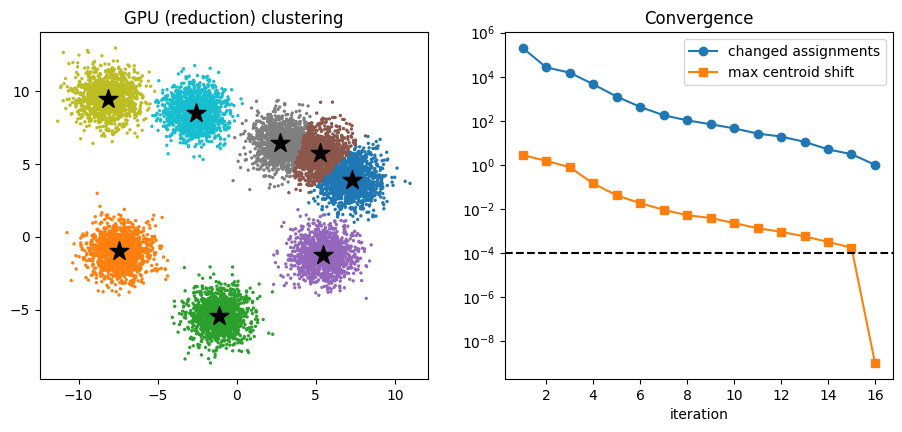

In [17]:
from kmeans_numpy import kmeans_numpy
A_np, C_np, it, hist = kmeans_numpy(X, K, history=True)
A_gpu = read_assign('a_red.bin'); C_gpu = read_points('c_red.bin')
print(f'NumPy: {it} iterations; agreement with GPU: {100*(A_np==A_gpu).mean():.3f}%  centroid max err {np.abs(C_np-C_gpu).max():.2e}')
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
ax[0].scatter(X[::20,0], X[::20,1], s=2, c=A_gpu[::20], cmap='tab10'); ax[0].scatter(C_gpu[:,0], C_gpu[:,1], marker='*', c='k', s=200); ax[0].set_title('GPU (reduction) clustering')
its=[h[0] for h in hist]; ax[1].semilogy(its, [max(h[1],1) for h in hist], 'o-', label='changed assignments'); ax[1].semilogy(its, [max(h[2],1e-9) for h in hist], 's-', label='max centroid shift'); ax[1].axhline(1e-4, ls='--', c='k'); ax[1].legend(); ax[1].set_xlabel('iteration'); ax[1].set_title('Convergence')
plt.show()

## 7 · Determinism check: run each strategy 3× and compare inertia bit-for-bit
Global float atomics execute in hardware-dependent order → the **atomic** result may differ in the last bits between runs. The **reduction** path sums partials in a fixed order → identical every run.

In [18]:
import subprocess, re
def run(mode):
    out = subprocess.run(['./kmeans_cuda','--data','blobs.bin','--k','8','--mode',mode,'--out-assign','/tmp/a.bin','--out-cent','/tmp/c.bin'],capture_output=True,text=True).stdout
    return re.search(r'inertia=(\S+)', out).group(1)
for mode in ('atomic','reduction'):
    print(mode, [run(mode) for _ in range(3)])

atomic ['3.736720e+05', '3.736720e+05', '3.736720e+05']
reduction ['3.736720e+05', '3.736720e+05', '3.736720e+05']


## 8 · Benchmark sweep (N × D × K, atomic vs reduction vs CPU)


{'mode': 'atomic', 'N': '100000', 'D': '2', 'K': '4', 'iters': '14', 'changed_last': '0', 'max_shift': '5.801e-06', 'time_ms': '4.055', 'assign_ms': '0.388', 'update_ms': '3.085', 'inertia': '1.999099e+05', 'shared_centroids': '1', 'gpu': 'Tesla T4', 'rep': 0}
{'mode': 'atomic', 'N': '100000', 'D': '2', 'K': '4', 'iters': '14', 'changed_last': '0', 'max_shift': '1.948e-05', 'time_ms': '3.916', 'assign_ms': '0.318', 'update_ms': '3.078', 'inertia': '1.999099e+05', 'shared_centroids': '1', 'gpu': 'Tesla T4', 'rep': 1}
{'mode': 'reduction', 'N': '100000', 'D': '2', 'K': '4', 'iters': '14', 'changed_last': '0', 'max_shift': '9.537e-07', 'time_ms': '1.601', 'assign_ms': '0.334', 'update_ms': '0.713', 'inertia': '1.999099e+05', 'shared_centroids': '1', 'gpu': 'Tesla T4', 'rep': 0}
{'mode': 'reduction', 'N': '100000', 'D': '2', 'K': '4', 'iters': '14', 'changed_last': '0', 'max_shift': '1.349e-06', 'time_ms': '1.598', 'assign_ms': '0.350', 'update_ms': '0.707', 'inertia': '1.999099e+05', 'sha

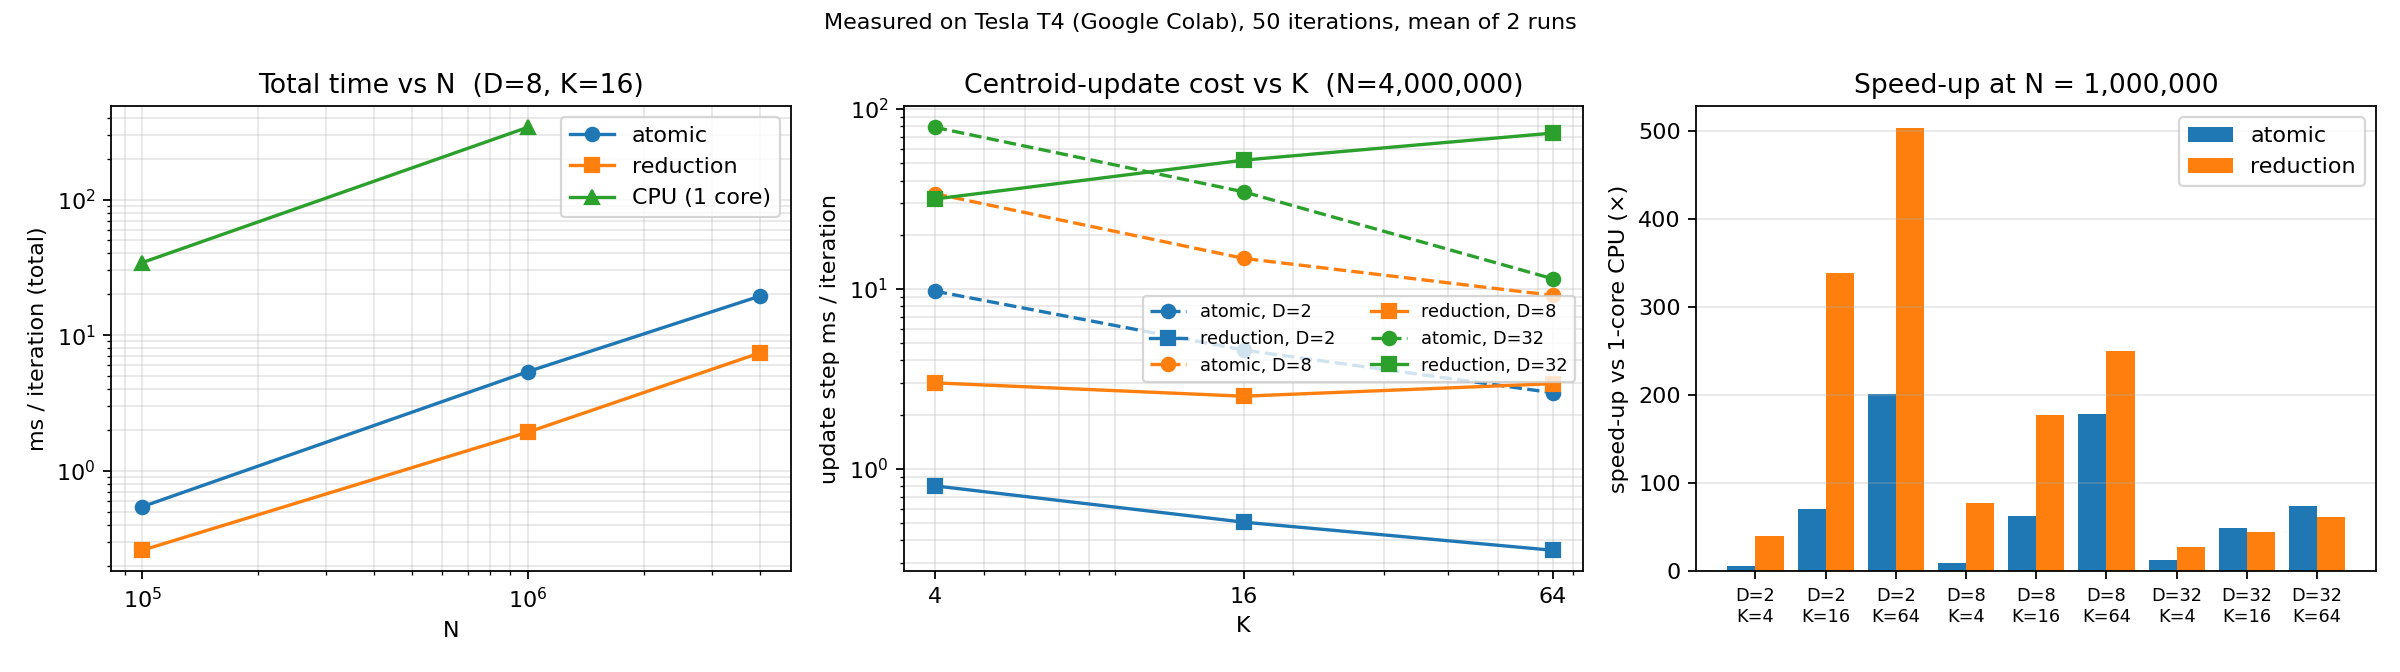

In [19]:
!python benchmark.py --exe ./kmeans_cuda --cpu ./kmeans_cpu --out benchmark.csv --sizes 100000,1000000,4000000 --dims 2,8,32 --ks 4,16,64 --repeat 2 --cpu-max-n 1000000
!python plot_results.py benchmark.csv fig5_gpu_benchmark.png
from IPython.display import Image; Image('fig5_gpu_benchmark.png')

In [20]:
import pandas as pd
df = pd.read_csv('benchmark.csv')
for c in ['N','D','K','iters']: df[c]=df[c].astype(int)
df['ms_per_iter'] = df['time_ms'].astype(float)/df['iters']
pivot = df.groupby(['N','D','K','mode'])['ms_per_iter'].mean().unstack('mode')
pivot['speedup_cpu/reduction'] = pivot['cpu']/pivot['reduction']
pivot['atomic/reduction'] = pivot['atomic']/pivot['reduction']
pivot.round(3)

mode            atomic       cpu  reduction  speedup_cpu/reduction  \
N       D  K                                                         
100000  2  4     0.285     3.208      0.114                 28.083   
           16    0.176    12.916      0.090                143.594   
           64    0.170    42.525      0.141                302.107   
        8  4     1.276    10.149      0.267                 37.986   
           16    0.543    34.254      0.259                132.154   
           64    0.943   138.636      0.704                196.856   
        32 4     3.656    33.820      1.317                 25.683   
           16    3.827   130.116      3.132                 41.548   
           64    7.910   521.759      8.781                 59.422   
1000000 2  4     5.269    30.963      0.778                 39.801   
           16    1.651   116.808      0.345                338.202   
           64    2.112   424.805      0.845                502.955   
        8  4    10.312    93.152      1.195                 77.984   
           16    5.379   340.875      1.923                177.265   
           64    7.529  1340.888      5.372                249.615   
        32 4    27.391   343.076     12.566                 27.302   
           16   26.887  1310.994     29.541                 44.379   
           64   70.746  5241.385     84.698                 61.883   
4000000 2  4    10.053       NaN      1.078                    NaN   
           16    5.158       NaN      1.163                    NaN   
           64    4.949       NaN      3.022                    NaN   
        8  4    35.070       NaN      4.359                    NaN   
           16   19.400       NaN      7.396                    NaN   
           64   27.417       NaN     21.479                    NaN   
        32 4    96.041       NaN     52.449                    NaN   
           16  102.340       NaN    124.817                    NaN   
           64  284.620       NaN    353.600                    NaN   

mode           atomic/reduction  
N       D  K                     
100000  2  4              2.492  
           16             1.954  
           64             1.209  
        8  4              4.778  
           16             2.095  
           64             1.339  
        32 4              2.777  
           16             1.222  
           64             0.901  
1000000 2  4              6.774  
           16             4.780  
           64             2.500  
        8  4              8.633  
           16             2.797  
           64             1.402  
        32 4              2.180  
           16             0.910  
           64             0.835  
4000000 2  4              9.325  
           16             4.437  
           64             1.638  
        8  4              8.045  
           16             2.623  
           64             1.276  
        32 4              1.831  
           16             0.820  
           64             0.805

## 9 · Profile one iteration with Nsight Systems (optional)
Shows the kernel timeline: `assign_kernel` dominates; `update_atomic_kernel` vs `update_partial_kernel + reduce_partials_kernel`.

In [21]:
!nsys profile --stats=true -o prof_red ./kmeans_cuda --data blobs.bin --k 8 --mode reduction --iters 5 2>/dev/null | grep -A12 'cuda_gpu_kern_sum' || echo 'nsys not available on this runtime'

[6/8] Executing 'cuda_gpu_kern_sum' stats report

 Time (%)  Total Time (ns)  Instances  Avg (ns)  Med (ns)  Min (ns)  Max (ns)  StdDev (ns)                                        Name                                       
 --------  ---------------  ---------  --------  --------  --------  --------  -----------  ---------------------------------------------------------------------------------
     50.7          371,222          5  74,244.4  69,054.0    68,158    87,198      8,301.4  update_partial_kernel(const float *, const int *, float *, int *, int, int, int) 
     29.1          212,762          5  42,552.4  42,271.0    42,015    43,262        559.2  assign_kernel(const float *, const float *, int *, int *, int, int, int, int)    
     16.5          120,445          5  24,089.0  24,032.0    23,999    24,223        109.6  reduce_partials_kernel(const float *, const int *, float *, int *, int, int, int)
      3.7           27,294          5   5,458.8   5,471.0     5,439     5,472   

## 10 · Download artefacts for the report
`benchmark.csv`, `fig5_gpu_benchmark.png` → copy into the project's `results/` and `figures/` folders.

In [22]:
from google.colab import files
files.download('benchmark.csv'); files.download('fig5_gpu_benchmark.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>